# Clase 8 — Segmentación de clientes con K-Means
**Aprendizaje Automático · Tecnicatura en Ciencia de Datos e IA**
**Alumna:** Mónica Frías

**Objetivo:** identificar cuántos segmentos latentes de clientes existen a partir de su comportamiento de compra y uso del sitio, sin etiquetas previas, y describir el perfil de cada segmento.

**Pasos:**
1. Carga y exploración del dataset
2. Selección de variables y escalado
3. Elección de k: método del codo (k = 2 a 6) y coeficiente de silueta como apoyo
4. Ajuste del modelo final y análisis de centroides
5. Perfiles de cada segmento y acciones sugeridas
6. Conclusiones

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)
RANDOM_STATE = 42

## 1. Carga y exploración del dataset

In [2]:
df = pd.read_csv('../Datos/dataset_segmentacion_clientes.csv')
print('Filas y columnas:', df.shape)
df.head()

Filas y columnas: (700, 7)


,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,noise_gauss,noise_uniform
0,11.152508,181.300834,33.564036,1.000000,0.800000,-1.806578,-2.516905
1,12.053451,178.637272,35.432081,0.784974,0.000000,0.645129,2.115460
2,2.203006,450.185298,7.030757,0.898297,0.000000,-0.047406,-0.724173
3,4.233314,89.006342,10.834453,0.000000,0.800000,0.901700,-2.974026
4,1.716799,449.773982,7.254548,0.000000,0.003279,0.386013,2.424522


In [3]:
df.info()
print('\nValores faltantes por columna:')
print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   purchase_freq_month   700 non-null    float64
 1   avg_basket_usd        700 non-null    float64
 2   time_on_site_min      700 non-null    float64
 3   discount_sensitivity  700 non-null    float64
 4   returns_rate          700 non-null    float64
 5   noise_gauss           700 non-null    float64
 6   noise_uniform         700 non-null    float64
dtypes: float64(7)
memory usage: 38.4 KB

Valores faltantes por columna:
purchase_freq_month     0
avg_basket_usd          0
time_on_site_min        0
discount_sensitivity    0
returns_rate            0
noise_gauss             0
noise_uniform           0
dtype: int64


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
purchase_freq_month,700.0,5.88,4.47,0.10,2.28,4.13,11.21,14.60
avg_basket_usd,700.0,248.17,154.90,86.99,90.77,180.22,449.72,452.97
time_on_site_min,700.0,16.78,12.91,3.16,6.60,9.97,34.34,38.35
discount_sensitivity,700.0,0.43,0.43,0.00,0.00,0.30,1.00,1.00
returns_rate,700.0,0.34,0.36,0.00,0.00,0.17,0.80,0.80
noise_gauss,700.0,0.02,1.01,-3.57,-0.65,0.08,0.73,2.86
noise_uniform,700.0,-0.01,1.68,-2.99,-1.42,0.01,1.41,3.00


El dataset tiene 700 clientes y 7 columnas, sin valores faltantes. Además de las 5 variables de la consigna aparecen dos columnas extra, `noise_gauss` y `noise_uniform`. Por su nombre y por sus valores (centradas en 0, sin relación con las demás, como se ve abajo) son **ruido agregado a propósito**: no describen ningún comportamiento del cliente.

In [5]:
variables = ['purchase_freq_month', 'avg_basket_usd', 'time_on_site_min',
             'discount_sensitivity', 'returns_rate']

df[variables + ['noise_gauss', 'noise_uniform']].corr().round(2)

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,noise_gauss,noise_uniform
purchase_freq_month,1.00,-0.49,0.97,0.19,-0.02,0.01,-0.02
avg_basket_usd,-0.49,1.00,-0.43,-0.08,0.09,0.03,0.06
time_on_site_min,0.97,-0.43,1.00,0.19,-0.01,0.01,-0.02
discount_sensitivity,0.19,-0.08,0.19,1.00,-0.01,-0.01,-0.04
returns_rate,-0.02,0.09,-0.01,-0.01,1.00,-0.05,0.01
noise_gauss,0.01,0.03,0.01,-0.01,-0.05,1.00,-0.05
noise_uniform,-0.02,0.06,-0.02,-0.04,0.01,-0.05,1.00


**Observaciones de la matriz de correlación:**
- `noise_gauss` y `noise_uniform` tienen correlación prácticamente nula con todo → confirman que son ruido y **se excluyen** del modelo. Si las dejáramos, K-Means también intentaría separar a los clientes según esas columnas y los grupos perderían sentido.
- `purchase_freq_month` y `time_on_site_min` están muy correlacionadas (≈ 0,97): los clientes que compran seguido también pasan mucho tiempo en el sitio.
- `avg_basket_usd` se relaciona negativamente con la frecuencia: quienes compran seguido tienden a gastar menos por compra.

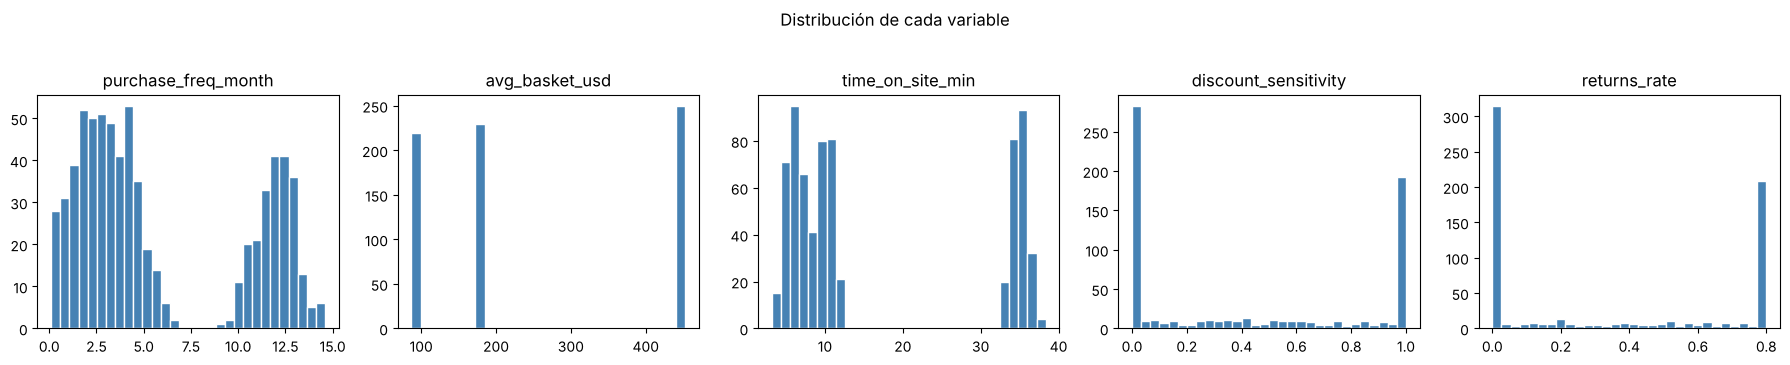

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))
for ax, col in zip(axes, variables):
    ax.hist(df[col], bins=30, color='steelblue', edgecolor='white')
    ax.set_title(col)
plt.suptitle('Distribución de cada variable', y=1.03)
plt.tight_layout()
plt.show()

Las distribuciones no son normales: tienen varios "picos" (por ejemplo, el ticket promedio se concentra cerca de 90, 180 y 450 USD, y la sensibilidad a descuentos se acumula en 0 y en 1). Eso ya sugiere que hay grupos de clientes bien diferenciados.

## 2. Escalado de las variables
Las variables están en escalas muy distintas: el ticket va de ~90 a ~450 USD, mientras que la sensibilidad a descuentos va de 0 a 1. Como K-Means usa **distancias euclidianas**, sin escalar el ticket dominaría todo el agrupamiento. Por eso se estandarizan con `StandardScaler` (media 0, desvío 1).

In [7]:
X = df[variables]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pd.DataFrame(X_scaled, columns=variables).describe().T[['mean', 'std']].round(2)

,mean,std
purchase_freq_month,-0.0,1.0
avg_basket_usd,-0.0,1.0
time_on_site_min,0.0,1.0
discount_sensitivity,0.0,1.0
returns_rate,-0.0,1.0


## 3. Elección de k
### 3.1 Método del codo (k = 2 a 6)
Para cada k se entrena K-Means (con inicialización `k-means++` y 10 inicializaciones distintas) y se guarda la **inercia** (suma de distancias al cuadrado de cada punto a su centroide). También se calcula el **coeficiente de silueta**, que mide qué tan bien separado está cada punto de los otros grupos (va de -1 a 1; más alto es mejor).

In [8]:
ks = range(2, 7)
inercias, siluetas = [], []
for k in ks:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=RANDOM_STATE)
    etiquetas = km.fit_predict(X_scaled)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_scaled, etiquetas))

resultados = pd.DataFrame({'k': list(ks), 'inercia': inercias, 'silueta': siluetas})
resultados['caida_inercia'] = -resultados['inercia'].diff()
resultados.round(3)

,k,inercia,silueta,caida_inercia
0,2,2088.881,0.400,NaN
1,3,1408.702,0.431,680.179
2,4,1173.438,0.429,235.264
3,5,997.742,0.420,175.696
4,6,762.466,0.461,235.276


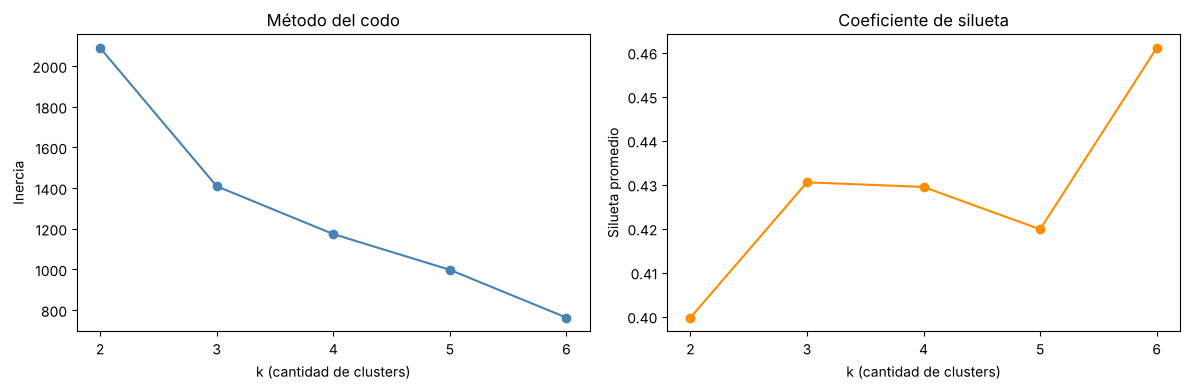

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(ks), inercias, 'o-', color='steelblue')
axes[0].set_title('Método del codo')
axes[0].set_xlabel('k (cantidad de clusters)')
axes[0].set_ylabel('Inercia')
axes[0].set_xticks(list(ks))

axes[1].plot(list(ks), siluetas, 'o-', color='darkorange')
axes[1].set_title('Coeficiente de silueta')
axes[1].set_xlabel('k (cantidad de clusters)')
axes[1].set_ylabel('Silueta promedio')
axes[1].set_xticks(list(ks))
plt.tight_layout()
plt.show()

### 3.2 Mirando un poco más allá de k = 6
El codo no es del todo nítido dentro de 2–6, así que se extiende el gráfico hasta k = 10 solo para ver dónde la curva se aplana definitivamente.

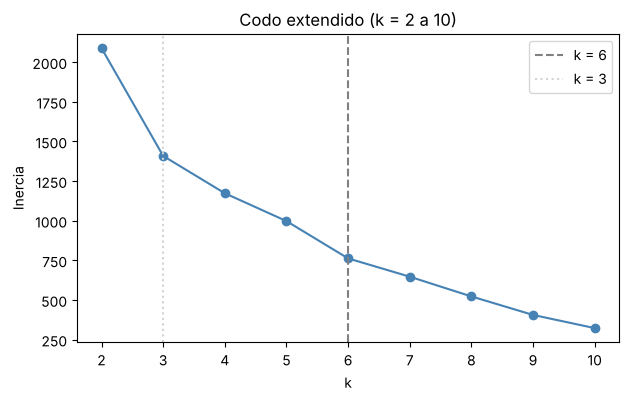

In [10]:
ks_ext = range(2, 11)
inercias_ext = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled).inertia_
                for k in ks_ext]

plt.figure(figsize=(7, 4))
plt.plot(list(ks_ext), inercias_ext, 'o-', color='steelblue')
plt.axvline(6, color='gray', linestyle='--', label='k = 6')
plt.axvline(3, color='lightgray', linestyle=':', label='k = 3')
plt.xticks(list(ks_ext))
plt.xlabel('k'); plt.ylabel('Inercia'); plt.title('Codo extendido (k = 2 a 10)')
plt.legend(); plt.show()

### 3.3 Justificación del valor de k
- **Primer codo en k = 3:** el salto más grande de inercia es de 2 a 3 grupos. Con k = 3 aparecen los tres tipos básicos de comprador (frecuente de ticket medio, esporádico de ticket alto, y ocasional de ticket bajo).
- **Segundo codo en k = 6:** entre 4 y 6 la inercia vuelve a caer fuerte (de 5 a 6 cae más que de 4 a 5), y **a partir de 6 la curva se aplana** (ver gráfico extendido).
- **La silueta es máxima en k = 6** (≈ 0,46), lo que indica que es la partición con grupos mejor separados dentro del rango pedido.

**Se elige k = 6.** Además de ser lo que indican las dos métricas, cada uno de los 6 grupos tiene una interpretación de negocio clara (sección 5). k = 3 se muestra también como una "vista resumida".

## 4. Modelo final con k = 6 y análisis de centroides

In [11]:
K = 6
kmeans = KMeans(n_clusters=K, init='k-means++', n_init=10, random_state=RANDOM_STATE)
df['cluster'] = kmeans.fit_predict(X_scaled)

print('Clientes por cluster:')
print(df['cluster'].value_counts().sort_index())

Clientes por cluster:
cluster
0    136
1    110
2    128
3    122
4    120
5     84
Name: count, dtype: int64


Los centroides que devuelve el modelo están en la escala estandarizada. Para poder interpretarlos se los vuelve a la **escala original** con `inverse_transform`.

In [12]:
centroides = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=variables)
centroides['n_clientes'] = df['cluster'].value_counts().sort_index().values
centroides.index.name = 'cluster'
centroides.round(2)

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,n_clientes
cluster,,,,,,
0,4.01,90.01,9.97,0.40,0.03,136
1,11.95,179.99,35.13,0.11,0.35,110
2,1.88,450.19,5.87,0.36,0.04,128
3,1.81,450.05,6.08,0.35,0.73,122
4,11.97,180.00,34.92,0.93,0.31,120
5,4.23,89.88,10.05,0.35,0.73,84


Para comparar los grupos entre sí conviene ver los centroides estandarizados: un valor positivo significa "por encima del promedio de todos los clientes" y uno negativo "por debajo".

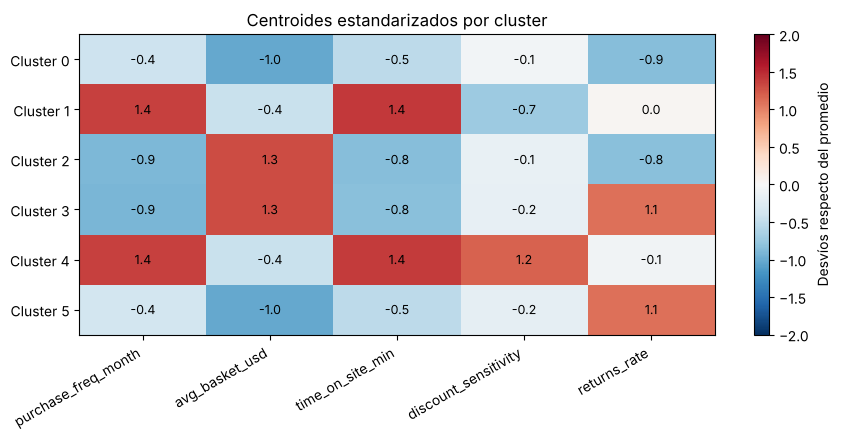

In [13]:
centroides_z = pd.DataFrame(kmeans.cluster_centers_, columns=variables)

fig, ax = plt.subplots(figsize=(9, 4.5))
im = ax.imshow(centroides_z.values, cmap='RdBu_r', vmin=-2, vmax=2, aspect='auto')
ax.set_xticks(range(len(variables)))
ax.set_xticklabels(variables, rotation=30, ha='right')
ax.set_yticks(range(K))
ax.set_yticklabels([f'Cluster {i}' for i in range(K)])
for i in range(K):
    for j in range(len(variables)):
        ax.text(j, i, f'{centroides_z.iloc[i, j]:.1f}', ha='center', va='center', fontsize=9)
plt.colorbar(im, label='Desvíos respecto del promedio')
plt.title('Centroides estandarizados por cluster')
plt.tight_layout()
plt.show()

### Visualización de los grupos
Para ver los clusters en un plano se reducen las 5 variables a 2 componentes con PCA (solo para graficar; el modelo se entrenó con las 5 variables).

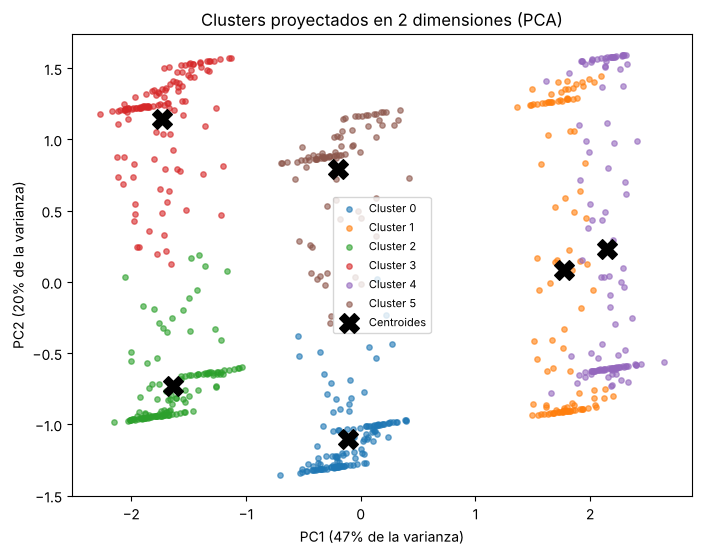

In [14]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
centros_pca = pca.transform(kmeans.cluster_centers_)

plt.figure(figsize=(8, 6))
for c in range(K):
    m = df['cluster'] == c
    plt.scatter(X_pca[m, 0], X_pca[m, 1], s=15, alpha=0.6, label=f'Cluster {c}')
plt.scatter(centros_pca[:, 0], centros_pca[:, 1], c='black', marker='X', s=200, label='Centroides')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%} de la varianza)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%} de la varianza)')
plt.title('Clusters proyectados en 2 dimensiones (PCA)')
plt.legend(fontsize=8)
plt.show()

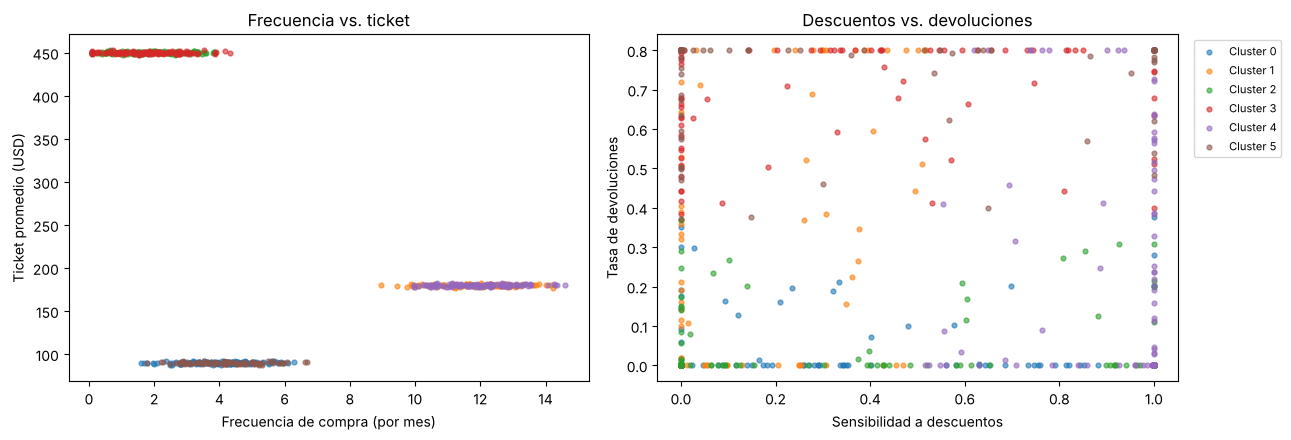

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for c in range(K):
    m = df['cluster'] == c
    axes[0].scatter(df.loc[m, 'purchase_freq_month'], df.loc[m, 'avg_basket_usd'], s=12, alpha=0.6, label=f'Cluster {c}')
    axes[1].scatter(df.loc[m, 'discount_sensitivity'], df.loc[m, 'returns_rate'], s=12, alpha=0.6, label=f'Cluster {c}')
axes[0].set_xlabel('Frecuencia de compra (por mes)'); axes[0].set_ylabel('Ticket promedio (USD)')
axes[0].set_title('Frecuencia vs. ticket')
axes[1].set_xlabel('Sensibilidad a descuentos'); axes[1].set_ylabel('Tasa de devoluciones')
axes[1].set_title('Descuentos vs. devoluciones')
axes[1].legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

El gráfico de la izquierda muestra **tres tipos de comprador** según frecuencia y ticket. El de la derecha muestra qué divide a cada uno de esos tres en dos: para los frecuentes es la **sensibilidad a descuentos**, y para los de ticket alto y ticket bajo es la **tasa de devoluciones**.

## 5. Perfiles de los segmentos
La tabla siguiente asigna a cada cluster un nombre a partir de sus centroides. Los nombres se asignan según los valores (no según el número de cluster), así el resultado no depende del orden en que K-Means numera los grupos.

In [16]:
def perfil(fila):
    if fila['purchase_freq_month'] > 8:
        base = 'Frecuente, ticket medio'
        extra = 'muy sensible a descuentos' if fila['discount_sensitivity'] > 0.5 else 'poco sensible a descuentos'
    elif fila['avg_basket_usd'] > 300:
        base = 'Esporádico, ticket alto'
        extra = 'devuelve mucho' if fila['returns_rate'] > 0.4 else 'casi no devuelve'
    else:
        base = 'Ocasional, ticket bajo'
        extra = 'devuelve mucho' if fila['returns_rate'] > 0.4 else 'casi no devuelve'
    return f'{base} · {extra}'

centroides['perfil'] = centroides.apply(perfil, axis=1)
centroides.sort_values(['purchase_freq_month', 'avg_basket_usd'], ascending=False).round(2)

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,n_clientes,perfil
cluster,,,,,,,
4,11.97,180.00,34.92,0.93,0.31,120,"Frecuente, ticket medio · muy sensible a descu..."
1,11.95,179.99,35.13,0.11,0.35,110,"Frecuente, ticket medio · poco sensible a desc..."
5,4.23,89.88,10.05,0.35,0.73,84,"Ocasional, ticket bajo · devuelve mucho"
0,4.01,90.01,9.97,0.40,0.03,136,"Ocasional, ticket bajo · casi no devuelve"
2,1.88,450.19,5.87,0.36,0.04,128,"Esporádico, ticket alto · casi no devuelve"
3,1.81,450.05,6.08,0.35,0.73,122,"Esporádico, ticket alto · devuelve mucho"


### Descripción de cada segmento y acción sugerida

| Segmento | Frecuencia | Ticket | Tiempo en sitio | Sens. descuentos | Devoluciones | Acción sugerida |
|---|---|---|---|---|---|---|
| **Frecuente · cazador de ofertas** | alta (~12/mes) | medio (~180 USD) | alto (~35 min) | muy alta (~0,9) | media | Foco para **promociones**, cupones y programas de puntos: responden al descuento y vuelven seguido. |
| **Frecuente · fiel sin descuento** | alta (~12/mes) | medio (~180 USD) | alto (~35 min) | muy baja (~0,1) | media | Clientes leales que compran sin incentivo: **no regalar margen** con descuentos; cuidar la experiencia y ofrecer suscripción o envío prioritario. |
| **Esporádico premium · conforme** | baja (~2/mes) | alto (~450 USD) | bajo (~6 min) | media | casi nula | El segmento más rentable por compra: foco en **upselling premium** y productos exclusivos. Compran rápido y saben lo que quieren. |
| **Esporádico premium · devuelve mucho** | baja (~2/mes) | alto (~450 USD) | bajo (~6 min) | media | muy alta (~0,73) | Compras grandes que vuelven: revisar **descripciones, talles y fotos** de los productos caros; considerar políticas de devolución. |
| **Ocasional económico · conforme** | media-baja (~4/mes) | bajo (~90 USD) | bajo (~10 min) | media | casi nula | Clientes de bajo valor pero estables: **cross-selling** y combos para subir el ticket. |
| **Ocasional económico · devuelve mucho** | media-baja (~4/mes) | bajo (~90 USD) | bajo (~10 min) | media | muy alta (~0,73) | El segmento menos rentable (ticket bajo + devoluciones): **investigar la causa** de las devoluciones antes de invertir en atraerlos. |

*(Los valores son aproximados; los exactos están en la tabla de centroides de arriba.)*

### Relación con los patrones que pedía la consigna
- **Frecuencia alta, ticket bajo y alta sensibilidad a descuentos:** aparece en el segmento *Frecuente · cazador de ofertas*. El ticket es "medio" (~180 USD) dentro del rango del dataset, más bajo que el premium.
- **Frecuencia baja, ticket alto y baja sensibilidad:** son los dos segmentos *Esporádico premium* (compras grandes y espaciadas). Su sensibilidad a descuentos es media en promedio, menor que la de los cazadores de ofertas.
- **Tiempo en sitio y devoluciones diferenciados:** el tiempo en sitio va de la mano de la frecuencia (los frecuentes exploran ~35 min, el resto entre 6 y 10). Las devoluciones, en cambio, **no dependen del tiempo en sitio**: dentro de los grupos de ticket alto y de ticket bajo hay clientes que casi no devuelven y otros que devuelven mucho.

### Vista resumida con k = 3
Como comparación, con k = 3 (el primer codo) el modelo encuentra solo los tres tipos de comprador; las diferencias en descuentos y devoluciones quedan mezcladas dentro de cada grupo.

In [17]:
km3 = KMeans(n_clusters=3, init='k-means++', n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
cent3 = pd.DataFrame(scaler.inverse_transform(km3.cluster_centers_), columns=variables)
cent3['n_clientes'] = np.bincount(km3.labels_)
cent3.round(2)

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,n_clientes
0,11.96,180.00,35.02,0.54,0.33,230
1,1.85,450.12,5.97,0.36,0.38,250
2,4.09,89.96,10.00,0.38,0.30,220


Se ve que con k = 3 la sensibilidad a descuentos y las devoluciones quedan en valores intermedios (0,3–0,5) en los tres grupos: son promedios de clientes muy distintos. Por eso k = 6 da segmentos más útiles para tomar decisiones.

## 6. Conclusiones
- Se excluyeron las columnas `noise_gauss` y `noise_uniform` por ser ruido sin relación con el comportamiento de los clientes.
- Fue necesario **escalar** las variables: el ticket (en USD) tiene una escala cientos de veces mayor que la sensibilidad a descuentos o la tasa de devoluciones, y sin escalar habría dominado el agrupamiento.
- El método del codo muestra un primer quiebre en **k = 3** y un segundo en **k = 6**, a partir del cual la inercia se aplana. El coeficiente de silueta es máximo en **k = 6**, por lo que se eligió ese valor.
- Los 6 segmentos se organizan en dos niveles: primero, **tres tipos de comprador** según frecuencia y ticket (frecuente de ticket medio, esporádico premium y ocasional económico); después, cada tipo se divide según **sensibilidad a descuentos** (en los frecuentes) o **tasa de devoluciones** (en los otros dos).
- Esto permite acciones distintas por segmento: promociones para los cazadores de ofertas, upselling para los premium, y revisión de productos y políticas para los grupos con muchas devoluciones.
- **Limitación:** K-Means supone grupos de forma esférica y tamaño parecido, y necesita fijar k de antemano. En este dataset funciona bien porque los grupos están bien separados, pero conviene validar los segmentos con información del negocio antes de usarlos.